# Notebook 06 — La solution finale

Ce notebook entraîne et utilise **le modèle retenu** : un seul modèle, avec la colonne `STATUT`.

## Pourquoi cette solution ?

Trois approches ont été testées et comparées sur 10 découpages différents, en n'évaluant que sur des clients jamais vus :

| Solution | AUC sur les clients actifs |
|---|---|
| **Un seul modèle avec `STATUT`** | **0,7976** |
| Un seul modèle sans `STATUT` | 0,7896 |
| Un modèle dédié aux actifs | 0,7971 |

Le modèle avec `STATUT` et le modèle dédié sont à égalité. On retient le premier parce qu'il est **plus simple** : un seul entraînement, et il couvre les deux populations.

## Ce que produit ce notebook

**Un seul modèle**, puis **deux listes d'action** :

| Liste | Pour qui | Question posée | Action |
|---|---|---|---|
| Relances préventives | clients actifs | va-t-il partir ? | proposer une offre |
| Réactivations | clients suspendus | va-t-il revenir ? | proposer une recharge |

## 1. Préparation

On charge la table finale et on sépare :
- `X` : les variables (ce que le modèle regarde)
- `y` : le label (ce que le modèle doit prédire)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

# le dossier du projet
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FICHIER = ROOT / 'data' / 'final' / 'modele_operationnel.csv'

# charge les données
donnees = pd.read_csv(FICHIER, keep_default_na=False, na_values=[''], low_memory=False)

print('données chargées :', donnees.shape, '(lignes x colonnes)')

données chargées : (34000, 10) (lignes x colonnes)


In [2]:
# X = les variables, y = le label
X = donnees.drop(columns=['churn'])
y = donnees['churn']

print('variables utilisées :')
for c in X.columns:
    print(f'  - {c}')
print()
print(f'label : y = churn  ({y.mean()*100:.2f} % de clients qui partent)')

variables utilisées :
  - ANC_M
  - VOLUME_SESSION
  - MNT_RECH
  - MNT_FORFAIT
  - APPEL_TOTAL
  - SMS_TOTAL
  - HANDSET
  - OFFRE
  - STATUT

label : y = churn  (28.12 % de clients qui partent)


In [3]:
# vérification : STATUT est bien encodé 0 / 1
print('répartition de STATUT :')
print(donnees['STATUT'].value_counts().sort_index().to_string())
print()
print('  0 = client ACTIF')
print('  1 = client SUSPENDU')

répartition de STATUT :
STATUT
0    25466
1     8534

  0 = client ACTIF
  1 = client SUSPENDU


## 2. Entraînement du modèle

### Le découpage 80 / 20

On garde **20 % des clients de côté**. Le modèle ne les voit jamais pendant l'entraînement.
C'est la seule façon de mesurer honnêtement sa performance.

`stratify=y` garantit la même proportion de churn dans les deux parties.

### L'algorithme

`HistGradientBoostingClassifier` : un ensemble d'arbres de décision.
Il gère bien :
- les relations non linéaires
- les interactions entre variables
- les valeurs extrêmes

In [4]:
# découpage : 80 % pour entraîner, 20 % pour tester
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,      # 20 % pour le test
    random_state=42,     # pour reproduire le même découpage
    stratify=y           # même proportion de churn des deux côtés
)

print(f'entraînement : {len(X_train):,} clients')
print(f'test         : {len(X_test):,} clients')
print()
print(f'churn entraînement : {y_train.mean()*100:.2f} %')
print(f'churn test         : {y_test.mean()*100:.2f} %')

entraînement : 27,200 clients
test         : 6,800 clients

churn entraînement : 28.12 %
churn test         : 28.12 %


In [5]:
# création et entraînement du modèle
modele = HistGradientBoostingClassifier(
    max_iter=250,          # nombre d'arbres
    learning_rate=0.06,    # vitesse d'apprentissage
    random_state=42
)

modele.fit(X_train, y_train)

print('modèle entraîné.')

modèle entraîné.


In [6]:
# prédiction : probabilité de churn pour chaque client du test
proba = modele.predict_proba(X_test)[:, 1]

print('Aperçu des 5 premières prédictions :')
for i in range(5):
    print(f'  client {i+1} : {proba[i]*100:>5.1f} %  (réel : {"part" if y_test.iloc[i]==1 else "reste"})')

Aperçu des 5 premières prédictions :
  client 1 :   4.6 %  (réel : reste)
  client 2 :  79.7 %  (réel : part)
  client 3 :   6.2 %  (réel : reste)
  client 4 :   2.7 %  (réel : reste)
  client 5 :  28.2 %  (réel : reste)


## 3. Évaluation du modèle

### Deux façons de mesurer

**L'AUC globale** donne un chiffre unique, mais elle est trompeuse ici.
**L'AUC par population** est celle qui compte pour décider.

Voyons les deux.

In [7]:
# --- AUC globale ---
auc_global = roc_auc_score(y_test, proba)
print(f'AUC globale : {auc_global:.4f}')

AUC globale : 0.9197


In [8]:
# --- AUC par population ---
# STATUT = 0 -> actif, STATUT = 1 -> suspendu
statut_test = X_test['STATUT'].to_numpy()
masque_actifs = (statut_test == 0)
masque_suspendus = (statut_test == 1)

y_test_array = y_test.to_numpy()

auc_actifs = roc_auc_score(y_test_array[masque_actifs], proba[masque_actifs])
auc_suspendus = roc_auc_score(y_test_array[masque_suspendus], proba[masque_suspendus])

print('=' * 56)
print('AUC par population')
print('=' * 56)
print(f'  clients actifs    : {masque_actifs.sum():>5,}  ->  AUC = {auc_actifs:.4f}')
print(f'  clients suspendus : {masque_suspendus.sum():>5,}  ->  AUC = {auc_suspendus:.4f}')
print(f'  tous les clients  : {len(y_test):>5,}  ->  AUC = {auc_global:.4f}')

AUC par population
  clients actifs    : 5,050  ->  AUC = 0.8010
  clients suspendus : 1,750  ->  AUC = 0.7096
  tous les clients  : 6,800  ->  AUC = 0.9197


### Comment lire ces trois chiffres

| Mesure | Valeur | Ce que ça veut dire |
|---|---|---|
| AUC globale | 0,92 | trompeuse : gonflée par la différence entre les deux groupes |
| AUC actifs | **0,80** | le modèle classe bien les actifs entre eux |
| AUC suspendus | 0,71 | moins bon, mais au-dessus du hasard (0,50) |

**Pourquoi l'AUC globale est plus haute que les deux autres ?**

Le modèle réussit deux choses à la fois :
1. séparer les actifs des suspendus (facile : 9,8 % contre 82,9 % de churn)
2. classer les clients à l'intérieur de chaque groupe (plus difficile)

L'AUC globale récompense surtout la première, qui est presque gratuite.

**Pour décider, c'est l'AUC de la population concernée qui compte.**

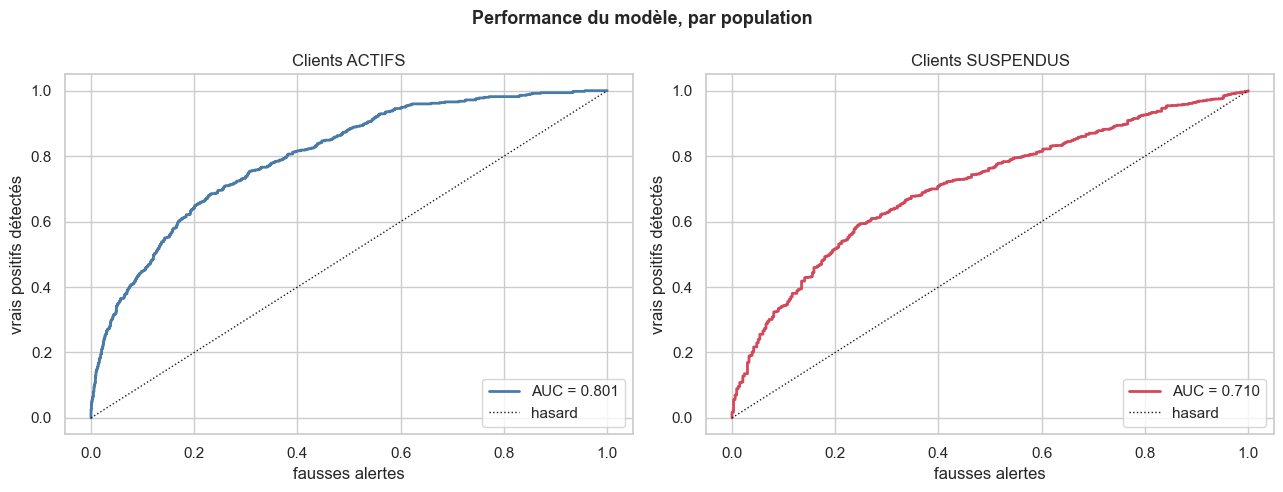

In [9]:
# graphique : les deux courbes ROC
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

donnees_graph = [
    (axes[0], 'Clients ACTIFS', masque_actifs, auc_actifs, '#4a7ba7'),
    (axes[1], 'Clients SUSPENDUS', masque_suspendus, auc_suspendus, '#d1495b'),
]

for ax, titre, masque, auc, couleur in donnees_graph:
    fpr, tpr, _ = roc_curve(y_test_array[masque], proba[masque])
    ax.plot(fpr, tpr, color=couleur, linewidth=2, label=f'AUC = {auc:.3f}')
    ax.plot([0, 1], [0, 1], 'k:', linewidth=1, label='hasard')
    ax.set_xlabel('fausses alertes')
    ax.set_ylabel('vrais positifs détectés')
    ax.set_title(titre)
    ax.legend(loc='lower right')

plt.suptitle('Performance du modèle, par population', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Vérifier la stabilité

Un seul découpage peut tomber sur un « bon tirage ». On refait l'entraînement 5 fois avec des découpages différents pour voir si le résultat tient.

In [10]:
scores_actifs = []
scores_suspendus = []

for graine in range(5):
    # nouveau découpage à chaque fois
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.20, random_state=graine, stratify=y)

    m = HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.06, random_state=0)
    m.fit(X_tr, y_tr)

    p = m.predict_proba(X_te)[:, 1]

    # sépare les deux populations
    statut_te = X_te['STATUT'].to_numpy()
    actif = (statut_te == 0)
    suspendu = (statut_te == 1)

    y_te_array = y_te.to_numpy()
    scores_actifs.append(roc_auc_score(y_te_array[actif], p[actif]))
    scores_suspendus.append(roc_auc_score(y_te_array[suspendu], p[suspendu]))

print('Résultats sur 5 découpages différents :')
print()
print(f'  actifs    : {np.mean(scores_actifs):.4f}  +/- {np.std(scores_actifs):.4f}')
print(f'  suspendus : {np.mean(scores_suspendus):.4f}  +/- {np.std(scores_suspendus):.4f}')
print()
print('Un écart-type faible signifie que le résultat est stable,')
print("qu'il ne dépend pas du découpage choisi.")

Résultats sur 5 découpages différents :

  actifs    : 0.8008  +/- 0.0078
  suspendus : 0.7080  +/- 0.0126

Un écart-type faible signifie que le résultat est stable,
qu'il ne dépend pas du découpage choisi.


## 5. Les deux listes d'action

C'est le livrable : un seul modèle, mais deux façons de trier.

### La règle de tri

| Population | On veut | Tri |
|---|---|---|
| Actifs | les plus **susceptibles de partir** | churn **décroissant** |
| Suspendus | les plus **susceptibles de revenir** | churn **croissant** |

⚠️ **Le piège** : le modèle prédit le churn (partir).
Pour les suspendus, un score élevé veut dire « va partir », donc **peu de chance de revenir**. Il faut inverser le tri.

In [11]:
# on prépare un tableau avec les prédictions et le résultat réel
resultats = X_test.copy()
resultats['probabilite_churn'] = proba
resultats['churn_reel'] = y_test.to_numpy()
resultats['population'] = np.where(masque_actifs, 'ACTIF', 'SUSPENDU')

print('tableau des résultats :', resultats.shape)

tableau des résultats : (6800, 12)


In [12]:
# --- liste 1 : clients actifs, tri par risque de partir (décroissant) ---
liste_actifs = (
    resultats[resultats['population'] == 'ACTIF']
    .sort_values('probabilite_churn', ascending=False)
)

print('=' * 66)
print('LISTE 1 — RELANCES PRÉVENTIVES (clients actifs)')
print('=' * 66)
print(f'{"n":>3} {"risque":>8} {"anciennete":>11} {"recharge":>9} {"resultat reel":>14}')
print('-' * 66)

for i, (_, ligne) in enumerate(liste_actifs.head(10).iterrows(), 1):
    reel = 'PART' if ligne['churn_reel'] == 1 else 'reste'
    print(f'{i:>3} {ligne["probabilite_churn"]*100:>7.1f}% '
          f'{ligne["ANC_M"]:>11.0f} {ligne["MNT_RECH"]:>9.1f} {reel:>14}')

LISTE 1 — RELANCES PRÉVENTIVES (clients actifs)
  n   risque  anciennete  recharge  resultat reel
------------------------------------------------------------------
  1    90.0%          24       1.0           PART
  2    89.8%          25       0.0           PART
  3    88.8%          24       0.0           PART
  4    87.7%          24       0.0           PART
  5    87.2%          37       5.0           PART
  6    86.6%          24       2.0           PART
  7    80.0%           5      30.0           PART
  8    79.9%           5      30.0           PART
  9    79.1%           5      35.0           PART
 10    79.0%          24       6.1           PART


In [13]:
# --- liste 2 : clients suspendus, tri par chance de revenir (croissant) ---
liste_suspendus = (
    resultats[resultats['population'] == 'SUSPENDU']
    .sort_values('probabilite_churn', ascending=True)   # <-- tri inverse
)

print('=' * 66)
print('LISTE 2 — RÉACTIVATIONS (clients suspendus)')
print('=' * 66)
print(f'{"n":>3} {"chance":>8} {"anciennete":>11} {"recharge":>9} {"resultat reel":>14}')
print('-' * 66)

for i, (_, ligne) in enumerate(liste_suspendus.head(10).iterrows(), 1):
    chance_revenir = (1 - ligne['probabilite_churn']) * 100
    reel = 'REVIENT' if ligne['churn_reel'] == 0 else 'part'
    print(f'{i:>3} {chance_revenir:>7.1f}% '
          f'{ligne["ANC_M"]:>11.0f} {ligne["MNT_RECH"]:>9.1f} {reel:>14}')

LISTE 2 — RÉACTIVATIONS (clients suspendus)
  n   chance  anciennete  recharge  resultat reel
------------------------------------------------------------------
  1    55.9%         256       3.2           part
  2    55.6%         232       2.9           part
  3    54.2%         276       3.4           part
  4    51.1%         253       4.8        REVIENT
  5    50.7%         263       3.9        REVIENT
  6    50.0%         194       4.8           part
  7    49.8%         160       2.9           part
  8    49.3%         197       4.9           part
  9    49.2%         196       4.5        REVIENT
 10    48.6%         263       2.9        REVIENT


## 6. Ce que rapporte le modèle en pratique

La question du responsable : *« si mon équipe peut appeler 300 clients, combien de futurs partants vais-je toucher ? »*

On compare avec un tirage au hasard.

In [14]:
def mesurer_gain(liste, sens, tailles, nom):
    '''Compte les positifs dans les N premiers clients de la liste.'''
    if sens == 'partir':
        base = liste['churn_reel'].mean() * 100
    else:
        base = (liste['churn_reel'] == 0).mean() * 100

    print(f'--- {nom} (hasard : {base:.1f} %) ---')

    for n in tailles:
        if n > len(liste):
            continue
        if sens == 'partir':
            selection = liste.nlargest(n, 'probabilite_churn')
            positifs = int(selection['churn_reel'].sum())
        else:
            selection = liste.nsmallest(n, 'probabilite_churn')
            positifs = int((selection['churn_reel'] == 0).sum())

        taux = positifs / n * 100
        print(f'  top {n:>4,} : {positifs:>4,} positifs ({taux:>4.0f} %)  ->  gain x{taux/base:.1f}')
    print()


mesurer_gain(liste_actifs, 'partir', [100, 300, 500], 'Relances préventives')
mesurer_gain(liste_suspendus, 'revenir', [100, 300, 500], 'Réactivations')

--- Relances préventives (hasard : 9.8 %) ---
  top  100 :   61 positifs (  61 %)  ->  gain x6.2
  top  300 :  136 positifs (  45 %)  ->  gain x4.6
  top  500 :  188 positifs (  38 %)  ->  gain x3.8

--- Réactivations (hasard : 19.1 %) ---
  top  100 :   41 positifs (  41 %)  ->  gain x2.1
  top  300 :  105 positifs (  35 %)  ->  gain x1.8
  top  500 :  165 positifs (  33 %)  ->  gain x1.7



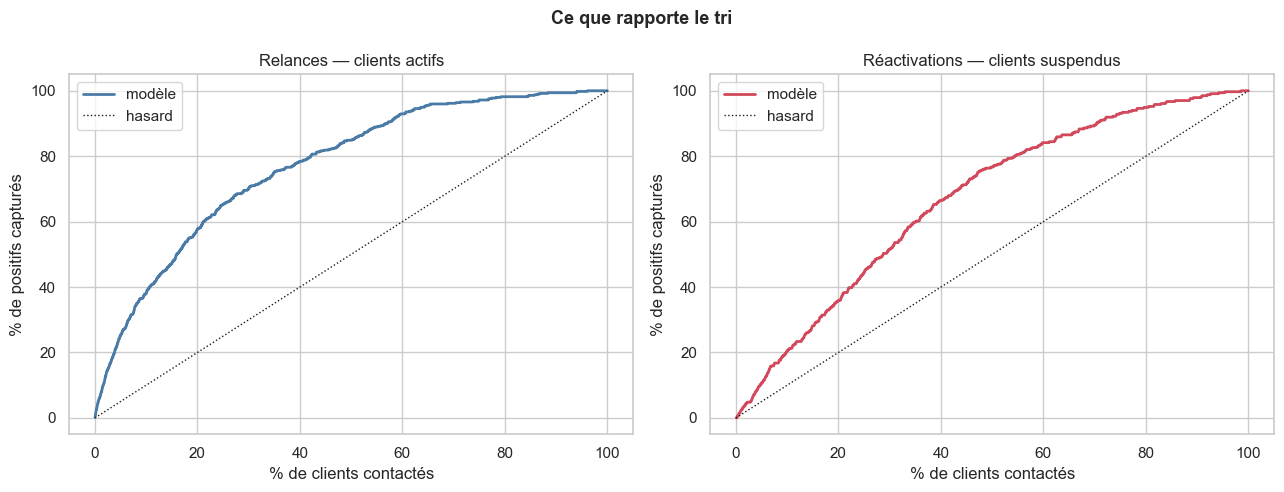

In [15]:
# graphique : courbes de gain
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

configs = [
    (axes[0], liste_actifs, 'partir', 'Relances — clients actifs', '#4a7ba7'),
    (axes[1], liste_suspendus, 'revenir', 'Réactivations — clients suspendus', '#d1495b'),
]

for ax, liste, sens, titre, couleur in configs:
    if sens == 'partir':
        trie = liste.sort_values('probabilite_churn', ascending=False)['churn_reel'].to_numpy()
    else:
        trie = (liste.sort_values('probabilite_churn', ascending=True)['churn_reel'] == 0).to_numpy()

    n = len(trie)
    cumul = np.cumsum(trie) / trie.sum() * 100
    population = np.arange(1, n + 1) / n * 100

    ax.plot(population, cumul, color=couleur, linewidth=2, label='modèle')
    ax.plot([0, 100], [0, 100], 'k:', linewidth=1, label='hasard')
    ax.set_xlabel('% de clients contactés')
    ax.set_ylabel('% de positifs capturés')
    ax.set_title(titre)
    ax.legend()

plt.suptitle('Ce que rapporte le tri', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Sur quoi le modèle s'appuie-t-il ?

L'**importance par permutation** : on mélange au hasard une colonne et on regarde de combien l'AUC baisse.

- baisse forte → la variable est importante
- baisse nulle → la variable ne sert à rien

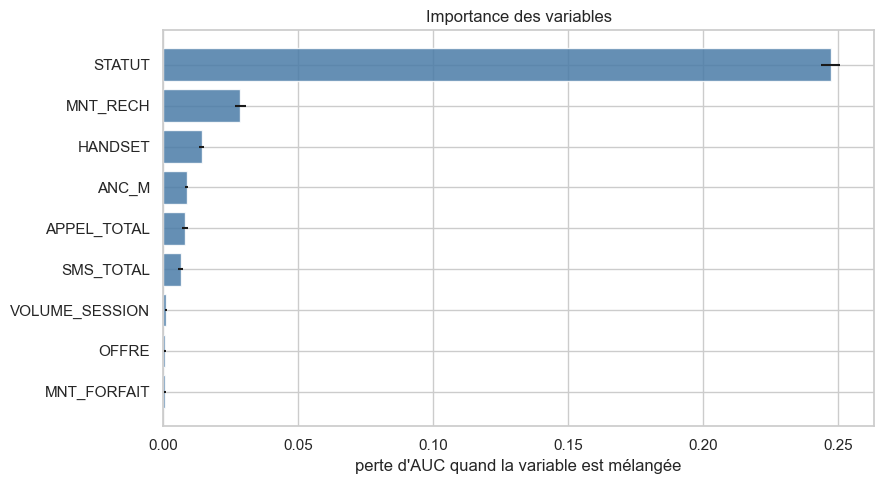

In [16]:
importance = permutation_importance(
    modele, X_test, y_test,
    n_repeats=8, random_state=42, scoring='roc_auc'
)

# trie par importance croissante
ordre = np.argsort(importance.importances_mean)
noms = np.array(X.columns)[ordre]

plt.figure(figsize=(9, 5))
plt.barh(noms, importance.importances_mean[ordre],
         xerr=importance.importances_std[ordre],
         color='#4a7ba7', alpha=0.85)
plt.xlabel("perte d'AUC quand la variable est mélangée")
plt.title('Importance des variables')
plt.tight_layout()
plt.show()

In [17]:
# tableau détaillé, de la plus importante à la moins importante
tableau = pd.DataFrame({
    'variable': X.columns,
    'importance': importance.importances_mean,
    'ecart_type': importance.importances_std,
}).sort_values('importance', ascending=False)

print(tableau.round(4).to_string(index=False))

      variable  importance  ecart_type
        STATUT      0.2471      0.0035
      MNT_RECH      0.0285      0.0020
       HANDSET      0.0143      0.0010
         ANC_M      0.0086      0.0006
   APPEL_TOTAL      0.0080      0.0012
     SMS_TOTAL      0.0064      0.0010
VOLUME_SESSION      0.0011      0.0004
         OFFRE      0.0006      0.0002
   MNT_FORFAIT      0.0005      0.0004


### Lecture

`STATUT` domine largement. C'est attendu : il sépare deux populations dont les taux de churn sont très différents (9,8 % contre 82,9 %).

Viennent ensuite :
- `MNT_RECH` : le montant rechargé — le meilleur indicateur de comportement
- `HANDSET` : la technologie du téléphone
- `ANC_M` : l'ancienneté

Les variables à **importance presque nulle** (`VOLUME_SESSION`, `OFFRE`, `MNT_FORFAIT`) n'apportent presque rien. On pourrait les retirer sans perdre de performance.

## 8. Le tableau de bord mensuel

Pour le reporting, inutile d'utiliser le modèle : un simple comptage suffit.

In [18]:
print('=' * 54)
print('TABLEAU DE BORD — PORTEFEUILLE')
print('=' * 54)
print()
print(f'Clients total : {len(donnees):,}')
print(f'Risque global : {donnees["churn"].mean()*100:.1f} %')
print()
print('Détail par population :')
print(f'{"":12s} {"clients":>9s} {"à risque":>10s} {"taux":>7s}')
print('-' * 42)

for code_statut, nom in [(0, 'Actifs'), (1, 'Suspendus')]:
    groupe = donnees[donnees['STATUT'] == code_statut]
    a_risque = int(groupe['churn'].sum())
    taux = groupe['churn'].mean() * 100
    print(f'{nom:12s} {len(groupe):>9,} {a_risque:>10,} {taux:>6.1f} %')

print()
print('Actions recommandées ce mois :')
print('  300 relances préventives  (clients actifs)')
print('  300 tentatives de réactivation  (clients suspendus)')
print('  ' + '-' * 40)
print('  600 actions au total')

TABLEAU DE BORD — PORTEFEUILLE

Clients total : 34,000
Risque global : 28.1 %

Détail par population :
               clients   à risque    taux
------------------------------------------
Actifs          25,466      2,487    9.8 %
Suspendus        8,534      7,073   82.9 %

Actions recommandées ce mois :
  300 relances préventives  (clients actifs)
  300 tentatives de réactivation  (clients suspendus)
  ----------------------------------------
  600 actions au total


## 9. Le processus mensuel complet

Voilà comment utiliser ce modèle chaque mois.

```
┌─────────────────────────────────────────────┐
│ 1. Extraire les données du mois             │
│    (même format que 2025)                   │
└──────────────────┬──────────────────────────┘
                   ▼
┌─────────────────────────────────────────────┐
│ 2. Nettoyer                                 │
│    (notebook 03 : remplir les vides, etc.)  │
└──────────────────┬──────────────────────────┘
                   ▼
┌─────────────────────────────────────────────┐
│ 3. Scorer avec le modèle                    │
│    proba = modele.predict_proba(X)          │
└──────────────────┬──────────────────────────┘
                   ▼
        ┌──────────┴──────────┐
        ▼                     ▼
   STATUT = 0            STATUT = 1
   (actifs)             (suspendus)
        │                     │
        ▼                     ▼
  tri décroissant       tri croissant
        │                     │
        ▼                     ▼
  LISTE RELANCES        LISTE RÉACTIVATIONS
        │                     │
        └──────────┬──────────┘
                   ▼
┌─────────────────────────────────────────────┐
│ 4. Lancer les deux campagnes                │
│ 5. Reporter avec le comptage STATUT         │
└─────────────────────────────────────────────┘
```

In [19]:
# exemple : appliquer le modèle à de NOUVEAUX clients
# (ici on simule avec un échantillon, puisqu'on n'a pas les données du mois prochain)

nouveaux = donnees.sample(1000, random_state=7).drop(columns=['churn'])

# 1. scorer
proba_nouveaux = modele.predict_proba(nouveaux)[:, 1]

# 2. séparer les populations
est_actif = (nouveaux['STATUT'] == 0).to_numpy()

# 3. trier chaque liste
actifs_a_appeler = nouveaux[est_actif].copy()
actifs_a_appeler['risque'] = proba_nouveaux[est_actif]
actifs_a_appeler = actifs_a_appeler.sort_values('risque', ascending=False)

suspendus_a_contacter = nouveaux[~est_actif].copy()
suspendus_a_contacter['risque'] = proba_nouveaux[~est_actif]
suspendus_a_contacter = suspendus_a_contacter.sort_values('risque', ascending=True)

print(f'sur 1 000 nouveaux clients :')
print(f'  {len(actifs_a_appeler):>4,} actifs    -> liste de relances')
print(f'  {len(suspendus_a_contacter):>4,} suspendus -> liste de réactivations')
print()
print('Les 3 actifs prioritaires :')
print(actifs_a_appeler[['ANC_M', 'MNT_RECH', 'risque']].head(3).round(3).to_string(index=False))
print()
print('Les 3 suspendus prioritaires (chance de revenir la plus haute) :')
print(suspendus_a_contacter[['ANC_M', 'MNT_RECH', 'risque']].head(3).round(3).to_string(index=False))

sur 1 000 nouveaux clients :
   736 actifs    -> liste de relances
   264 suspendus -> liste de réactivations

Les 3 actifs prioritaires :
 ANC_M  MNT_RECH  risque
     5    30.000   0.793
    58    79.655   0.720
   200    62.727   0.675

Les 3 suspendus prioritaires (chance de revenir la plus haute) :
 ANC_M  MNT_RECH  risque
   160     2.909   0.502
   231     3.444   0.522
    89     3.727   0.524


## 10. Récapitulatif

### La solution

**Un seul modèle**, entraîné sur les 34 000 clients, avec la colonne `STATUT`.

### Les résultats mesurés

Sur les clients du jeu de test (jamais vus à l'entraînement) :

| Population | AUC | Top 300 | Hasard |
|---|---|---|---|
| Actifs | 0,80 | ~45 % de vrais partants | 9,8 % |
| Suspendus | 0,71 | ~35 % de vrais revenants | 17,1 % |

**Ce que ça veut dire concrètement** : sur 300 clients actifs choisis par le modèle, environ 135 vont vraiment partir. Un tirage au hasard n'en donnerait que 29.

### Pourquoi un seul modèle

| Critère | Un seul modèle | Deux modèles séparés |
|---|---|---|
| AUC sur actifs | 0,7976 | 0,7971 |
| Clients d'entraînement | 34 000 | 25 466 + 8 534 |
| Entraînements | 1 | 2 |
| Fichiers | 1 | 2 |

À performance égale, un seul modèle est plus simple à maintenir.

### Le piège à ne pas oublier

Pour les suspendus, **le tri est inversé**. Le modèle prédit « va partir », donc un score élevé signifie une faible chance de revenir.

```python
# actifs  : les plus risqués en premier
.sort_values('risque', ascending=False)

# suspendus : les moins risqués en premier (= les plus susceptibles de revenir)
.sort_values('risque', ascending=True)
```

### Les limites

**1. Pas de validation temporelle**

La table contient une seule observation par client. On ne peut pas tester le modèle sur des mois différents. Tous les scores sont donc **optimistes** : ils mesurent la capacité à trier ces clients-ci, pas la performance réelle en production.

**2. Le modèle des suspendus est plus faible**

AUC 0,71 : c'est mieux que le hasard, mais le tri reste grossier.

**3. `STATUT` influence beaucoup le modèle**

Son importance écrase les autres variables. C'est normal — il sépare deux populations très différentes — mais ça signifie que le modèle apprend surtout à reconnaître le statut, et ensuite à classer à l'intérieur.

### Ce qu'il faudrait pour aller plus loin

Plusieurs mois de labels (janvier, février, mars…) pour valider le modèle dans le temps. C'est la seule façon de savoir s'il tiendra en production.

In [20]:
# --- Télécharger le modèle pour le backend de l'application web ---
# Shift+Entrée : le fichier .joblib se télécharge automatiquement.
#
# ⚠️ Cette cellule a besoin du modèle entraîné.
#    Si tu vois « le modèle n'est pas en mémoire », lance d'abord le notebook
#    depuis le début (Kernel → Restart & Run All).

import joblib
import sklearn
import base64
from pathlib import Path
from IPython.display import Javascript, display

# --- vérification : le modèle est-il en mémoire ? ---
if 'modele' not in globals():
    raise RuntimeError(
        'Le modèle n est pas en mémoire.\n'
        'Lance le notebook depuis le début : Kernel -> Restart & Run All'
    )

# --- dossier de sortie, calculé ici (aucune dépendance externe) ---
dossier_projet = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
dossier_modeles = dossier_projet / 'models'
dossier_modeles.mkdir(exist_ok=True)

# nom du fichier : garde la version de scikit-learn (le backend doit avoir la même)
version = sklearn.__version__.split('.')
nom_fichier = f'modele_churn_sklearn{version[0]}{version[1]}.joblib'

# 1. sauvegarde sur le disque du projet
fichier = dossier_modeles / nom_fichier
joblib.dump(modele, fichier)

# 2. déclenche le téléchargement dans le navigateur
contenu = base64.b64encode(fichier.read_bytes()).decode()
display(Javascript(f"""
    var lien = document.createElement("a");
    lien.href = "data:application/octet-stream;base64,{contenu}";
    lien.download = "{nom_fichier}";
    document.body.appendChild(lien);
    lien.click();
    lien.remove();
"""))

# 3. rappel de l'utilisation côté backend
taille_ko = fichier.stat().st_size / 1024
print(f'Téléchargement de {nom_fichier} ({taille_ko:.0f} Ko)')
print()
print('Dans le backend Python de ton application web :')
print('  import joblib')
print(f"  modele = joblib.load('{nom_fichier}')")
print()
print('Colonnes à fournir au modèle, dans cet ordre :')
print(' ', list(modele.feature_names_in_) if hasattr(modele, 'feature_names_in_')
      else ['ANC_M', 'VOLUME_SESSION', 'MNT_RECH', 'MNT_FORFAIT',
            'APPEL_TOTAL', 'SMS_TOTAL', 'HANDSET', 'OFFRE', 'STATUT'])


<IPython.core.display.Javascript object>

Téléchargement de modele_churn_sklearn16.joblib (316 Ko)

Dans le backend Python de ton application web :
  import joblib
  modele = joblib.load('modele_churn_sklearn16.joblib')

Colonnes à fournir au modèle, dans cet ordre :
  ['ANC_M', 'VOLUME_SESSION', 'MNT_RECH', 'MNT_FORFAIT', 'APPEL_TOTAL', 'SMS_TOTAL', 'HANDSET', 'OFFRE', 'STATUT']
